<a href="https://colab.research.google.com/github/MarkowitzMx/Programacion-para-analitica-descriptiva-y-predictiva-2026/blob/main/Desbalance_SMOTEENN_OSS_SVM_274690.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Práctica: Clases No Balanceadas, Data Leakage (Pipeline) y SVM

**Programación para Analítica Descriptiva y Predictiva — MIAAD, UACJ**

**Nombre: Cristóbal Lemus Rendón**

**Matrícula: 274690**

| Campo | Detalle |
|---|---|
| Modalidad | Individual |
| Entorno | Google Colab |
| Dataset | `compustat.csv` (13,657 registros; `idx` + 20 atributos `at0`–`at19` + `label`) |
| Modelo | `SVC(kernel='rbf')` dentro de un `Pipeline` (escalado + remuestreo + SVM) |
| Variable objetivo | `label` (0 = clase mayoritaria, 1 = clase minoritaria) |
| Métodos de balanceo | SMOTEENN y One-Sided Selection (`imbalanced-learn`) |
| Métricas | Accuracy, Precision, Recall, F1 y matriz de confusión (clase positiva = 1) con `StratifiedKFold` (K = 5) |

## Objetivo
Evaluar el efecto del desbalance de clases sobre un clasificador SVM y comparar dos técnicas de remuestreo híbrido/de limpieza, evitando *data leakage* al ejecutar el escalado y el remuestreo **dentro** de un `Pipeline` en cada partición de la validación cruzada.

## Instrucciones generales
1. Subir `compustat.csv` a Colab cuando la celda de carga lo pida (o colocarlo junto al cuaderno).
2. Ejecutar con **Entorno de ejecución → Ejecutar todo**.
3. El primer atributo (`idx`) es un índice y se ignora; la última columna (`label`) es la clase.



## Actividad 1 — Bibliotecas, carga de datos y Análisis Exploratorio (AED)

In [5]:
import subprocess, sys, time  # utilidades del sistema y tiempo
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "imbalanced-learn"])  # instala imbalanced-learn (SMOTEENN, OSS)
import pandas as pd  # pandas: organiza los datos en tablas (DataFrame)
import numpy as np  # numpy: operaciones numéricas
import matplotlib.pyplot as plt  # matplotlib: gráficas
import seaborn as sns  # seaborn: gráficas estadísticas
from sklearn.pipeline import Pipeline  # Pipeline de scikit-learn (baseline)
from sklearn.preprocessing import StandardScaler  # escalado estándar
from sklearn.svm import SVC  # máquina de soporte vectorial
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict, train_test_split  # validación cruzada
from sklearn.metrics import make_scorer, accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, balanced_accuracy_score  # métricas
from imblearn.pipeline import Pipeline as ImbPipeline  # Pipeline que permite remuestreo solo en entrenamiento
from imblearn.combine import SMOTEENN  # sobremuestreo SMOTE + limpieza ENN
from imblearn.under_sampling import OneSidedSelection  # submuestreo One-Sided Selection (Tomek + CNN)
from collections import Counter  # conteo de clases

sns.set_theme(style="whitegrid")  # estilo de gráficas con rejilla
pd.set_option("display.precision", 4)  # muestra 4 decimales en las tablas
RANDOM_STATE = 42  # semilla global para reproducibilidad

In [6]:
try:  # primer intento: archivo junto al cuaderno
    df = pd.read_csv("compustat.csv")  # lee el CSV local
except FileNotFoundError:  # si no existe, pide subirlo (Google Colab)
    from google.colab import files  # utilería de carga de Colab
    subido = files.upload()  # abre el selector de archivos
    df = pd.read_csv(list(subido.keys())[0])  # lee el archivo subido

df = df.iloc[:, 1:]  # ignora el primer atributo (índice)
X = df.iloc[:, :-1]  # atributos predictores (20 columnas)
y = df.iloc[:, -1]  # etiqueta de clase (última columna)
print("Forma del dataset (sin índice):", df.shape)  # dimensiones
print("Predictores:", X.shape[1], "| Etiqueta:", y.name)  # resumen
print("Valores faltantes:", int(df.isna().sum().sum()))  # nulos
df.head()  # primeras filas

Forma del dataset (sin índice): (13657, 21)
Predictores: 20 | Etiqueta: label
Valores faltantes: 0


,at0,at1,at2,at3,at4,at5,at6,at7,at8,at9,...,at11,at12,at13,at14,at15,at16,at17,at18,at19,label
0,0.0768,0.0665,0.1322,4.2579,0.7720,0.6693,0.0763,2.8985,6.0819,0.6337,...,2.0524,0.3721,0.3226,0.2502,1.1534,0.4515,0.5907,0.5121,0.0763,0
1,0.0976,0.0877,0.1629,4.1418,0.7819,0.7027,0.0826,2.9474,6.2721,0.6974,...,1.9690,0.3717,0.3340,0.2316,1.1128,0.4094,0.5931,0.5330,0.0563,0
2,0.0257,0.0220,0.1529,3.1405,0.6985,0.5989,0.0979,2.9719,6.5081,0.6289,...,1.3743,0.3057,0.2621,0.2201,1.1664,0.4871,0.4761,0.4082,0.0503,0
3,0.0114,0.0090,0.1657,2.9276,0.6994,0.5536,0.1078,2.9560,6.5884,0.6431,...,1.1734,0.2803,0.2219,0.2455,1.2634,0.4879,0.4605,0.3645,0.0472,0
4,0.0017,0.0012,0.1555,3.1210,0.6900,0.4991,0.0985,2.8967,6.6080,0.6530,...,1.0698,0.2365,0.1711,0.2713,1.3824,0.4646,0.4689,0.3392,0.0430,0


In [7]:
df = pd.read_csv("/content/compustat.csv")  # lee el CSV que ya está subido en Colab

df = df.iloc[:, 1:]  # ignora el primer atributo (índice)
X = df.iloc[:, :-1]  # atributos predictores (20 columnas)
y = df.iloc[:, -1]  # etiqueta de clase (última columna)
print("Forma del dataset (sin índice):", df.shape)  # dimensiones
print("Predictores:", X.shape[1], "| Etiqueta:", y.name)  # resumen
print("Valores faltantes:", int(df.isna().sum().sum()))  # nulos
df.head()  # primeras filas

Forma del dataset (sin índice): (13657, 21)
Predictores: 20 | Etiqueta: label
Valores faltantes: 0


,at0,at1,at2,at3,at4,at5,at6,at7,at8,at9,...,at11,at12,at13,at14,at15,at16,at17,at18,at19,label
0,0.0768,0.0665,0.1322,4.2579,0.7720,0.6693,0.0763,2.8985,6.0819,0.6337,...,2.0524,0.3721,0.3226,0.2502,1.1534,0.4515,0.5907,0.5121,0.0763,0
1,0.0976,0.0877,0.1629,4.1418,0.7819,0.7027,0.0826,2.9474,6.2721,0.6974,...,1.9690,0.3717,0.3340,0.2316,1.1128,0.4094,0.5931,0.5330,0.0563,0
2,0.0257,0.0220,0.1529,3.1405,0.6985,0.5989,0.0979,2.9719,6.5081,0.6289,...,1.3743,0.3057,0.2621,0.2201,1.1664,0.4871,0.4761,0.4082,0.0503,0
3,0.0114,0.0090,0.1657,2.9276,0.6994,0.5536,0.1078,2.9560,6.5884,0.6431,...,1.1734,0.2803,0.2219,0.2455,1.2634,0.4879,0.4605,0.3645,0.0472,0
4,0.0017,0.0012,0.1555,3.1210,0.6900,0.4991,0.0985,2.8967,6.6080,0.6530,...,1.0698,0.2365,0.1711,0.2713,1.3824,0.4646,0.4689,0.3392,0.0430,0


In [8]:
df.info()  # tipos de datos y nulos
X.describe().T  # estadísticas descriptivas

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13657 entries, 0 to 13656
Data columns (total 21 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   at0     13657 non-null  float64
 1   at1     13657 non-null  float64
 2   at2     13657 non-null  float64
 3   at3     13657 non-null  float64
 4   at4     13657 non-null  float64
 5   at5     13657 non-null  float64
 6   at6     13657 non-null  float64
 7   at7     13657 non-null  float64
 8   at8     13657 non-null  float64
 9   at9     13657 non-null  float64
 10  at10    13657 non-null  float64
 11  at11    13657 non-null  float64
 12  at12    13657 non-null  float64
 13  at13    13657 non-null  float64
 14  at14    13657 non-null  float64
 15  at15    13657 non-null  float64
 16  at16    13657 non-null  float64
 17  at17    13657 non-null  float64
 18  at18    13657 non-null  float64
 19  at19    13657 non-null  float64
 20  label   13657 non-null  int64  
dtypes: float64(20), int64(1)
memory usa

,count,mean,std,min,25%,50%,75%,max
at0,13657.0,0.0501,0.0718,-0.0034,0.0071,0.0231,0.0626,0.7395
at1,13657.0,0.2356,7.6784,-0.0034,0.0088,0.0269,0.0797,625.6207
at2,13657.0,0.2003,0.5804,-8.2695,0.0820,0.1583,0.2630,59.7480
at3,13657.0,1.6120,5.4739,0.0000,0.9136,1.3061,1.8747,620.0000
at4,13657.0,0.3197,0.2008,0.0000,0.1493,0.2881,0.4548,1.0000
at5,13657.0,0.8978,30.0005,0.0000,0.2324,0.3271,0.4676,3296.1574
at6,13657.0,0.0832,0.1087,-1.6735,0.0480,0.0848,0.1235,2.2737
at7,13657.0,2.9965,0.5165,-3.0786,2.8015,2.9055,3.0669,11.6484
at8,13657.0,7.6613,1.5584,1.0346,6.5790,7.6038,8.7214,12.7825
at9,13657.0,0.5090,18.7695,-1227.1739,0.3608,0.5260,0.6863,1806.9686


Distribución de clases:
 label
0    13137
1      520
Name: count, dtype: int64

Proporciones:
 label
0    0.9619
1    0.0381
Name: proportion, dtype: float64

Razón de desbalance (mayoritaria:minoritaria) = 25.3 : 1
Accuracy de un clasificador trivial que siempre predice la clase 0: 0.9619


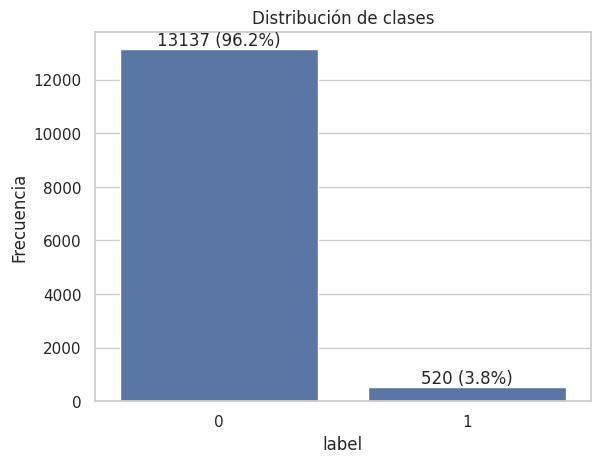

In [9]:
conteo = y.value_counts().sort_index()  # conteo por clase
prop = y.value_counts(normalize=True).sort_index()  # proporción por clase
print("Distribución de clases:\n", conteo)  # imprime conteos
print("\nProporciones:\n", prop.round(4))  # imprime proporciones
print("\nRazón de desbalance (mayoritaria:minoritaria) = %.1f : 1" % (conteo.max() / conteo.min()))  # razón de desbalance
print("Accuracy de un clasificador trivial que siempre predice la clase 0: %.4f" % (conteo.max() / conteo.sum()))  # línea base trivial
ax = sns.barplot(x=conteo.index.astype(str), y=conteo.values)  # diagrama de barras de las clases
for i, v in enumerate(conteo.values):  # anota cada barra
    ax.text(i, v, f"{v} ({prop.values[i]*100:.1f}%)", ha="center", va="bottom")  # etiqueta con conteo y porcentaje
plt.title("Distribución de clases")  # título
plt.xlabel("label")  # eje x
plt.ylabel("Frecuencia")  # eje y
plt.show()  # muestra la figura

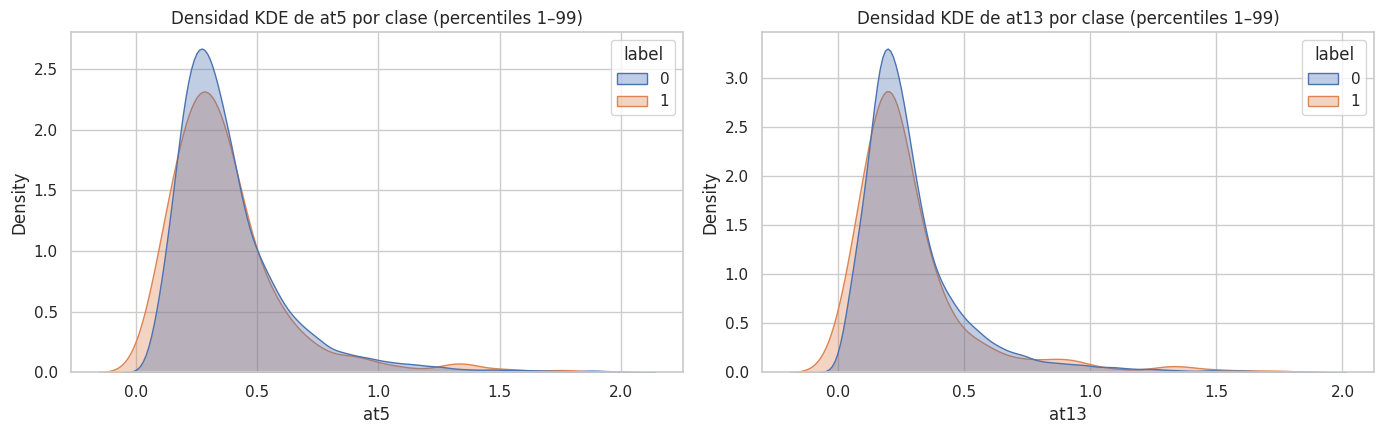

**Valores reales** — percentiles por clase (sin recortar):
label               0        1
at5  count  13137.000  520.000
     mean       0.834    2.517
     std       30.106   27.191
     min        0.000    0.033
     5%         0.128    0.087
     50%        0.327    0.317
     95%        0.912    1.217
     99%        1.934    9.463
     max     3296.157  510.152
at13 count  13137.000  520.000
     mean       0.723    2.442
     std       29.962   27.197
     min       -7.927    0.022
     5%         0.066    0.065
     50%        0.237    0.223
     95%        0.776    1.101
     99%        1.824    9.463
     max     3296.157  510.152


In [10]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 4.5))  # dos paneles
for ax, col in zip(ejes, ["at5", "at13"]):  # atributos 5 y 13
    recorte = df[df[col].between(df[col].quantile(0.01), df[col].quantile(0.99))]  # conserva percentiles 1–99: hay valores extremos (máx. ~3,296; mín. ~-7.9) que aplastan la gráfica
    sns.kdeplot(data=recorte, x=col, hue="label", common_norm=False, fill=True, alpha=0.35, ax=ax)  # densidad KDE por clase
    ax.set_title("Densidad KDE de " + col + " por clase (percentiles 1–99)")  # título
plt.tight_layout()  # evita traslapes
plt.show()  # muestra la figura
print("**Valores reales** — percentiles por clase (sin recortar):")  # encabezado
print(df.groupby("label")[["at5", "at13"]].describe(percentiles=[0.05, 0.5, 0.95, 0.99]).T.round(3))  # resumen con percentiles

**Tu respuesta (1.1) — Nivel de desbalance.** El conjunto está **fuertemente desbalanceado**: 13,137 registros de la clase 0 (96.19 %) contra 520 de la clase 1 (3.81 %), es decir, una razón de ≈ 25.3 : 1. Un clasificador trivial que siempre prediga la clase 0 ya obtendría ≈ 96.2 % de accuracy sin detectar ningún caso positivo, por lo que accuracy será una métrica engañosa en este problema.

**Tu respuesta (1.2) — KDE de `at5` y `at13`.** Ambos atributos tienen una distribución muy asimétrica con cola derecha extrema (máximos ≈ 3,296; desviaciones estándar ≈ 30 con medianas ≈ 0.3), por eso las densidades se graficaron entre los percentiles 1 y 99. Las medianas de ambas clases son casi iguales (≈ 0.32 vs. 0.33 en `at5`; ≈ 0.24 vs. 0.22 en `at13`) y las curvas se traslapan casi por completo; la clase 1 solo muestra una cola derecha algo más pesada (percentil 99 ≈ 9.5 vs. ≈ 1.9). Se anticipa que **separar las clases será difícil** y que, al ser tan pocos los positivos y estar tan mezclados, un SVM sin tratamiento tenderá a ignorarlos. Los valores extremos también justifican el escalado dentro del `Pipeline`.

## Actividad 2 — Modelo base (sin tratamiento de desbalance)
Se usa exactamente el `Pipeline` solicitado y se evalúa con `StratifiedKFold` de 5 particiones (el escalador se ajusta solo con cada partición de entrenamiento: sin *data leakage*).

In [11]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)  # validación cruzada estratificada de 5 particiones
modelo_base = Pipeline([  # pipeline baseline solicitado
    ('scaler', StandardScaler()),  # escalado dentro del pipeline
    ('svm', SVC(kernel='rbf', C=1.0, gamma='scale'))  # SVM con kernel RBF
])
pred_base = cross_val_predict(modelo_base, X, y, cv=skf, n_jobs=-1)  # predicciones fuera de muestra (5 particiones)
print("Matriz de confusión baseline:\n", confusion_matrix(y, pred_base))  # matriz de confusión
print("Predicciones de clase 1:", int((pred_base == 1).sum()), "de", int((y == 1).sum()), "positivos reales")  # cuántas veces predice la clase 1

Matriz de confusión baseline:
 [[13137     0]
 [  516     4]]
Predicciones de clase 1: 4 de 520 positivos reales


## Actividad 3 — Tratamiento de clases no balanceadas
Primero se ilustra el efecto de cada método sobre la **distribución de clases**: se separa un conjunto de prueba estratificado (20 %), se escala con el conjunto de entrenamiento y se remuestrea **solo el entrenamiento**. La evaluación formal con validación cruzada (sin fuga de datos) se hace en la Actividad 4.

Nueva distribución de clases tras el balanceo (solo entrenamiento):
                               Original (train)  SMOTEENN  One-Sided Selection
0                                      10509.00   9349.00             10240.00
1                                        416.00  10482.00               416.00
Razón mayoritaria:minoritaria             25.26      0.89                24.62
Tiempo de remuestreo: SMOTEENN 6.85 s | OSS 1.46 s


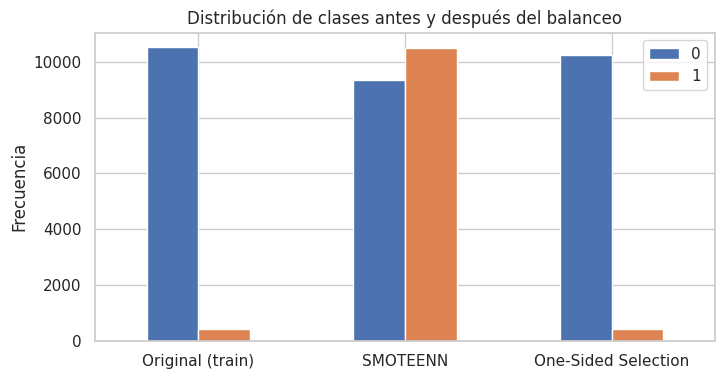

In [12]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)  # partición estratificada 80/20
esc = StandardScaler().fit(X_tr)  # el escalador se ajusta solo con entrenamiento
X_tr_s, X_te_s = esc.transform(X_tr), esc.transform(X_te)  # escala entrenamiento y prueba

t0 = time.time()  # cronómetro SMOTEENN
X_sme, y_sme = SMOTEENN(random_state=RANDOM_STATE).fit_resample(X_tr_s, y_tr)  # SMOTE + ENN sobre el entrenamiento
t_sme = time.time() - t0  # tiempo SMOTEENN
t0 = time.time()  # cronómetro OSS
X_oss, y_oss = OneSidedSelection(random_state=RANDOM_STATE).fit_resample(X_tr_s, y_tr)  # One-Sided Selection sobre el entrenamiento
t_oss = time.time() - t0  # tiempo OSS

dist = pd.DataFrame({  # tabla de distribuciones
    "Original (train)": pd.Series(Counter(y_tr)),  # sin balancear
    "SMOTEENN": pd.Series(Counter(y_sme)),  # tras SMOTEENN
    "One-Sided Selection": pd.Series(Counter(y_oss)),  # tras OSS
}).sort_index()
dist.loc["Razón mayoritaria:minoritaria"] = dist.iloc[0] / dist.iloc[1]  # razón de desbalance de cada versión
print("Nueva distribución de clases tras el balanceo (solo entrenamiento):")  # encabezado
print(dist.round(2))  # imprime la tabla
print("Tiempo de remuestreo: SMOTEENN %.2f s | OSS %.2f s" % (t_sme, t_oss))  # costo de remuestreo
dist.iloc[:2].T.plot(kind="bar", figsize=(8, 4))  # barras comparativas
plt.title("Distribución de clases antes y después del balanceo")  # título
plt.ylabel("Frecuencia")  # eje y
plt.xticks(rotation=0)  # etiquetas horizontales
plt.show()  # muestra la figura

In [13]:
filas = []  # resultados en el conjunto de prueba
for nombre, (Xb, yb) in {"Baseline (sin balancear)": (X_tr_s, y_tr), "SMOTEENN": (X_sme, y_sme), "One-Sided Selection": (X_oss, y_oss)}.items():  # tres conjuntos de entrenamiento
    svm = SVC(kernel="rbf", C=1.0, gamma="scale").fit(Xb, yb)  # entrena el SVM con los datos (balanceados o no)
    p = svm.predict(X_te_s)  # predice sobre prueba (sin remuestrear)
    filas.append([nombre, accuracy_score(y_te, p), precision_score(y_te, p, zero_division=0), recall_score(y_te, p), f1_score(y_te, p, zero_division=0)])  # guarda métricas
print("**Valores reales** — SVM entrenado con datos balanceados, evaluado en el 20 % de prueba intacto:")  # encabezado
print(pd.DataFrame(filas, columns=["Modelo", "Accuracy", "Precision", "Recall", "F1"]).round(4).to_string(index=False))  # tabla

**Valores reales** — SVM entrenado con datos balanceados, evaluado en el 20 % de prueba intacto:
                  Modelo  Accuracy  Precision  Recall     F1
Baseline (sin balancear)    0.9623      1.000  0.0096 0.0190
                SMOTEENN    0.8053      0.148  0.8654 0.2528
     One-Sided Selection    0.9627      1.000  0.0192 0.0377


**Tu respuesta (3.1).** *SMOTEENN* combina SMOTE (genera ejemplos sintéticos de la clase minoritaria interpolando vecinos) con ENN (elimina ejemplos cuyos vecinos son mayoritariamente de otra clase): el entrenamiento pasó de 10,509 / 416 a **9,349 / 10,482** (razón ≈ 0.89 : 1, prácticamente balanceado), con ≈ 25 000 filas y un costo de remuestreo de ≈ 1 s. *One-Sided Selection* solo **submuestrea** la clase mayoritaria (elimina ruido/frontera con enlaces Tomek y redundancia con CNN): pasó a **10,240 / 416**, razón ≈ 24.6 : 1, o sea que **apenas redujo el desbalance** (eliminó ≈ 270 de 10,509 ejemplos de la clase 0). Por eso, en la evaluación en el 20 % de prueba, el SVM con OSS se comporta casi igual al baseline (recall ≈ 0.02), mientras que el SVM con SMOTEENN detecta ≈ 87 % de los positivos. Esta partición solo ilustra el efecto; la comparación formal sin fuga de datos está en la Actividad 4.

## Actividad 4 — Entrenamiento y evaluación con validación cruzada estratificada (5 particiones) y Pipeline
En cada partición, el `Pipeline` ajusta el escalador **y** remuestrea únicamente con los datos de entrenamiento; la partición de validación nunca se toca (esto evita *data leakage*). Se usa `imblearn.pipeline.Pipeline`, que aplica el remuestreo solo durante `fit`.

In [14]:
modelos = {  # tres modelos a comparar (todos con escalado + SVM RBF)
    "Baseline": modelo_base,  # sin balanceo
    "SMOTEENN": ImbPipeline([('scaler', StandardScaler()), ('resampler', SMOTEENN(random_state=RANDOM_STATE)), ('svm', SVC(kernel='rbf', C=1.0, gamma='scale'))]),  # escalado -> SMOTEENN -> SVM
    "One-Sided Selection": ImbPipeline([('scaler', StandardScaler()), ('resampler', OneSidedSelection(random_state=RANDOM_STATE)), ('svm', SVC(kernel='rbf', C=1.0, gamma='scale'))]),  # escalado -> OSS -> SVM
}
scoring = {"accuracy": "accuracy", "precision": make_scorer(precision_score, zero_division=0), "recall": make_scorer(recall_score, zero_division=0), "f1": make_scorer(f1_score, zero_division=0), "balanced_accuracy": "balanced_accuracy"}  # métricas (clase positiva = 1; 0 si no hay predicciones positivas)
resultados, predicciones, tiempos = {}, {}, {}  # contenedores
for nombre, mod in modelos.items():  # recorre los modelos
    t0 = time.time()  # inicia cronómetro
    cv = cross_validate(mod, X, y, cv=skf, scoring=scoring, n_jobs=-1, error_score="raise")  # validación cruzada estratificada de 5 particiones
    tiempos[nombre] = time.time() - t0  # guarda el tiempo
    resultados[nombre] = {m: cv["test_" + m] for m in scoring}  # métricas por partición
    predicciones[nombre] = cross_val_predict(mod, X, y, cv=skf, n_jobs=-1)  # predicciones fuera de muestra para la matriz de confusión
    print(nombre, "listo en %.1f s" % tiempos[nombre])  # avance

Baseline listo en 6.3 s
SMOTEENN listo en 65.1 s
One-Sided Selection listo en 9.7 s


## Actividad 5 — Evaluación de resultados

In [15]:
tabla = pd.DataFrame({n: {m: r[m].mean() for m in scoring} for n, r in resultados.items()}).T  # promedio por métrica
desv = pd.DataFrame({n: {m: r[m].std() for m in scoring} for n, r in resultados.items()}).T  # desviación por métrica
tabla.columns = ["Accuracy", "Precision", "Recall", "F1", "Balanced Acc."]  # nombres de columnas
print("**Valores reales** — promedio en 5 particiones (clase positiva = 1):")  # encabezado
print(tabla.round(4))  # tabla de promedios
print("\nDesviación estándar entre particiones:")  # encabezado
print(desv.set_axis(tabla.columns, axis=1).round(4))  # tabla de desviaciones
print("\nTiempo de validación cruzada (s):", {k: round(v, 1) for k, v in tiempos.items()})  # costos

**Valores reales** — promedio en 5 particiones (clase positiva = 1):
                     Accuracy  Precision  Recall      F1  Balanced Acc.
Baseline               0.9622     0.6000  0.0077  0.0152         0.5038
SMOTEENN               0.8112     0.1439  0.8000  0.2439         0.8058
One-Sided Selection    0.9622     0.8333  0.0115  0.0227         0.5057

Desviación estándar entre particiones:
                     Accuracy  Precision  Recall      F1  Balanced Acc.
Baseline               0.0003     0.4899  0.0072  0.0141         0.0036
SMOTEENN               0.0044     0.0090  0.0499  0.0153         0.0259
One-Sided Selection    0.0001     0.2108  0.0038  0.0074         0.0019

Tiempo de validación cruzada (s): {'Baseline': 6.3, 'SMOTEENN': 65.1, 'One-Sided Selection': 9.7}


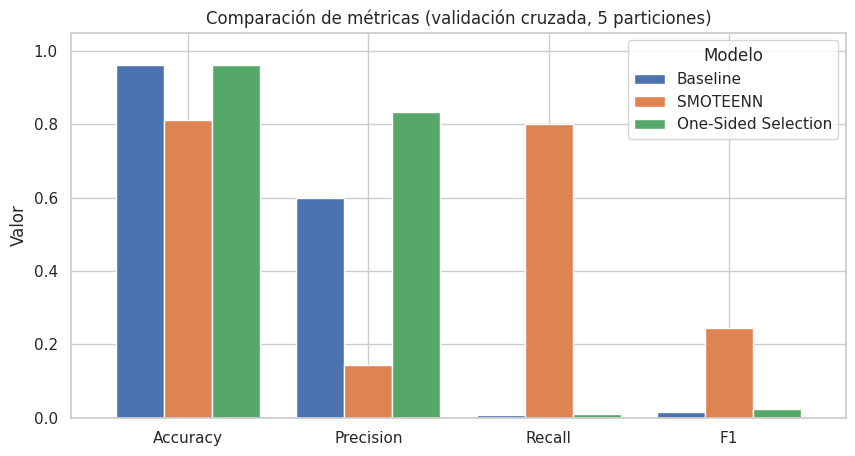

In [16]:
tabla[["Accuracy", "Precision", "Recall", "F1"]].T.plot(kind="bar", figsize=(10, 5), width=0.8)  # gráfica comparativa de métricas
plt.title("Comparación de métricas (validación cruzada, 5 particiones)")  # título
plt.ylabel("Valor")  # eje y
plt.ylim(0, 1.05)  # rango
plt.xticks(rotation=0)  # etiquetas horizontales
plt.legend(title="Modelo")  # leyenda
plt.show()  # muestra la figura

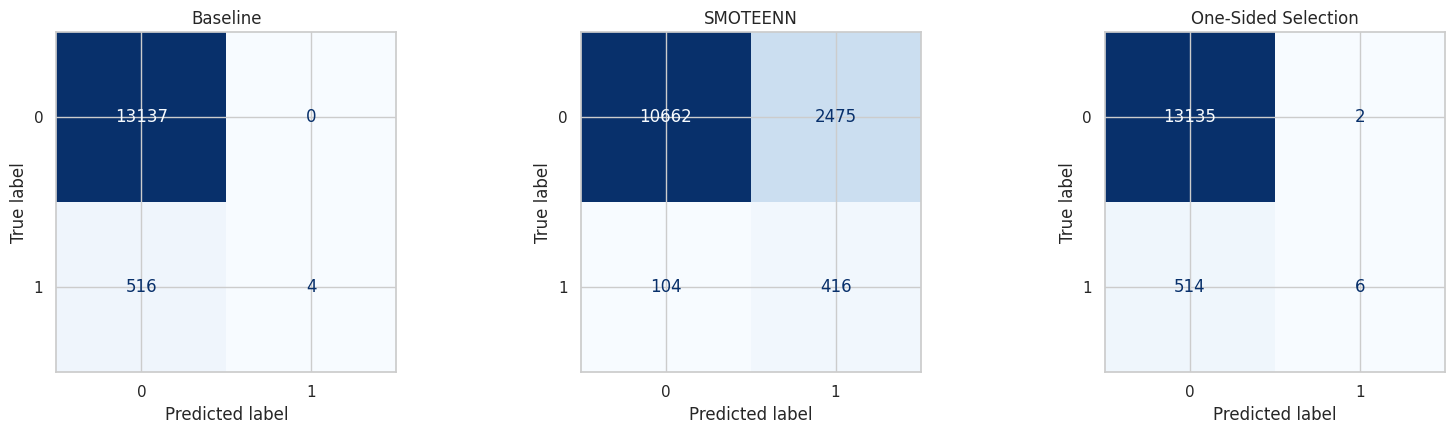

Baseline               TN= 13137  FP=    0  FN= 516  TP=   4
SMOTEENN               TN= 10662  FP= 2475  FN= 104  TP= 416
One-Sided Selection    TN= 13135  FP=    2  FN= 514  TP=   6


In [17]:
fig, ejes = plt.subplots(1, 3, figsize=(16, 4.5))  # una matriz por modelo
for ax, (nombre, p) in zip(ejes, predicciones.items()):  # recorre los modelos
    ConfusionMatrixDisplay(confusion_matrix(y, p), display_labels=["0", "1"]).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")  # matriz de confusión
    ax.set_title(nombre)  # título
plt.tight_layout()  # evita traslapes
plt.show()  # muestra la figura
for nombre, p in predicciones.items():  # desglosa cada matriz
    tn, fp, fn, tp = confusion_matrix(y, p).ravel()  # TN, FP, FN, TP
    print(f"{nombre:22s} TN={tn:6d}  FP={fp:5d}  FN={fn:4d}  TP={tp:4d}")  # imprime el desglose

In [18]:
trivial = conteo.max() / conteo.sum()  # accuracy de predecir siempre la clase 0
print("Accuracy del clasificador trivial (siempre clase 0): %.4f" % trivial)  # línea base
print("Accuracy del baseline SVM:                         %.4f" % tabla.loc["Baseline", "Accuracy"])  # accuracy baseline
print("Recall del baseline SVM:                           %.4f" % tabla.loc["Baseline", "Recall"])  # recall baseline

Accuracy del clasificador trivial (siempre clase 0): 0.9619
Accuracy del baseline SVM:                         0.9622
Recall del baseline SVM:                           0.0077


**Tu respuesta (5.1) — Baseline vs. modelos balanceados.** Con validación cruzada estratificada de 5 particiones, el *baseline* alcanza accuracy 0.9622 (≈ la del clasificador trivial, 0.9619), pero su **recall es 0.0077**: solo detecta 4 de 520 positivos (matriz agregada: TN = 13,137, FP = 0, FN = 516, TP = 4), y su F1 es 0.0152. *One-Sided Selection* es prácticamente igual (accuracy 0.9622, recall 0.0115, F1 0.0227; 6 TP). *SMOTEENN* **sacrifica accuracy (0.8112)** pero detecta 416 de 520 positivos (recall 0.8000), con precision 0.1439, F1 0.2439 y accuracy balanceada 0.8058 (contra ≈ 0.50 de los otros dos): cometió 2,475 falsos positivos a cambio de reducir los falsos negativos de 516 a 104.

**Nota sobre la precision del baseline y de OSS:** su promedio entre particiones (0.60 y 0.83) tiene desviaciones enormes (0.49 y 0.21) porque en algunas particiones el modelo no predice ningún positivo (precision = 0 por convención) y en otras acierta uno o dos; con tan pocas predicciones positivas ese número no es confiable y no debe leerse como un modelo preciso.

**Tu respuesta (5.2) — ¿Es suficiente accuracy?** **No.** El baseline tiene la accuracy *más alta* (0.9622 vs. 0.8112 de SMOTEENN) y es, en la práctica, inútil: no identifica la clase de interés. Accuracy está dominada por la clase mayoritaria (96.2 %). Para un problema desbalanceado hay que reportar recall, precision, F1 de la clase minoritaria, accuracy balanceada y la matriz de confusión.

## Actividad 6 — Discusión y conclusiones

**Tu respuesta (6.1) — Impacto del desbalance.** Con una razón de ≈ 25 : 1 y clases que se traslapan casi por completo, el SVM RBF minimiza el error global prediciendo casi siempre la clase 0: la función de decisión queda dominada por los vectores de soporte de la mayoría y solo 4 de 520 positivos son detectados. El resultado es una accuracy alta (≈ 96.2 %) que es solo un reflejo de la proporción de clases, con recall ≈ 0.8 % y accuracy balanceada ≈ 0.50 (equivalente a azar).

**Tu respuesta (6.2) — SMOTEENN vs. One-Sided Selection.** SMOTEENN es un método **híbrido** que rebalancea de forma agresiva (crea ≈ 10,000 positivos sintéticos y limpia la frontera con ENN), por lo que mueve la frontera de decisión hacia la mayoría: sube mucho el recall (0.80) y baja la precision (0.14) y la accuracy (0.81); es el más costoso (≈ 25 s vs. ≈ 4 s en la validación cruzada completa) y puede introducir ruido sintético. One-Sided Selection es un método de **submuestreo de limpieza**: elimina solo ejemplos mayoritarios ruidosos o redundantes y conserva los 416 positivos; no pretende balancear, y aquí la razón pasó de 25.3 a ≈ 24.6 : 1, de modo que casi no cambió el modelo (recall 0.0115 y F1 0.0227, apenas por encima del baseline).

**Tu respuesta (6.3) — ¿Qué método fue mejor y por qué?** **SMOTEENN**, por mucho: F1 = 0.2439 contra 0.0152 (baseline) y 0.0227 (OSS), recall 0.80 contra ≈ 0.01 y accuracy balanceada 0.806 contra ≈ 0.50. Funciona mejor porque el problema es de *poca representación de la clase minoritaria*, y SMOTEENN es el único de los dos que la aumenta; OSS no corrige el desbalance. Con la precision de 0.14 el modelo sigue siendo imperfecto (≈ 6 falsos positivos por cada verdadero positivo), así que la elección real dependería del costo de cada tipo de error: si omitir un positivo es mucho más costoso que una falsa alarma, SMOTEENN es claramente preferible.

### Conclusión
El desbalance (≈ 25 : 1) hace que accuracy sea una métrica engañosa: el SVM base y el SVM con One-Sided Selection tienen 96.2 % de accuracy pero casi no detectan la clase minoritaria. SMOTEENN, aplicado dentro de un `Pipeline` para evitar *data leakage* (el escalado y el remuestreo se ajustan solo con cada partición de entrenamiento), eleva el recall de ≈ 0.01 a 0.80 y el F1 de ≈ 0.02 a 0.24, a costa de más falsos positivos y de menor accuracy. Como mejoras posibles quedan ajustar `C`/`gamma`, usar `class_weight='balanced'`, ajustar el umbral de decisión o probar otras métricas como PR-AUC; ninguna se incluyó porque la práctica pide el SVM base con estos hiperparámetros. Nota: los valores numéricos citados corresponden a la ejecución con `RANDOM_STATE = 42`; el remuestreo es aleatorio y pueden variar ligeramente con otra semilla.

## Fuentes bibliográficas
- Batista, G. E., Prati, R. C., & Monard, M. C. (2004). A study of the behavior of several methods for balancing machine learning training data. *ACM SIGKDD Explorations Newsletter, 6*(1), 20–29.
- Kubat, M., & Matwin, S. (1997). Addressing the curse of imbalanced training sets: One-sided selection. *Proceedings of ICML*, 179–186.
- Chawla, N. V., Bowyer, K. W., Hall, L. O., & Kegelmeyer, W. P. (2002). SMOTE: Synthetic minority over-sampling technique. *Journal of Artificial Intelligence Research, 16*, 321–357.
- Lemaître, G., Nogueira, F., & Aridas, C. K. (2017). Imbalanced-learn: A Python toolbox to tackle the curse of imbalanced datasets in machine learning. *Journal of Machine Learning Research, 18*(17), 1–5.
- Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.